# Fraud Detection in Digital Financial Transactions

**Problem statement.** Digital financial transactions are increasing, and fraudulent activities can cause
significant financial losses. Traditional rule-based detection systems may fail to identify complex suspicious
patterns. This system uses machine learning to analyse transaction behaviour, identify anomalies and flag
potentially fraudulent activities.

**Data.** Kaggle [`computingvictor/transactions-fraud-datasets`](https://www.kaggle.com/datasets/computingvictor/transactions-fraud-datasets)
(the dataset used in the [Financial transactions EDA notebook](https://www.kaggle.com/code/jigneshkirtinagda/financial-transactions)):
~13.3M card transactions (2010–2019), 2,000 customers, 6,146 cards, and fraud labels for ~8.9M transactions.

**Approach.**
1. Clean & merge users, cards and transactions (as in the reference EDA notebook).
2. Engineer transaction, *behavioural* (past-only velocity / deviation / novelty), card and customer features.
3. Compare four detectors on a strict **time-based** hold-out (2019):
   rule-based baseline · Isolation Forest (unsupervised anomaly detection) · Logistic Regression · LightGBM.
4. Explain each flag with SHAP, and pick operating thresholds on validation data.

> Heavy steps run in `scripts/train.py` (≈10 min on a laptop). This notebook loads its outputs from `data/processed/` and `models/`.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from fraud import config, data, features, models, explain, evaluate

plt.style.use("ggplot")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Data loading and cleaning
Money columns are stored as strings like `$-77.00`; we strip `$` and cast, parse dates, and join cards → users → transactions.

In [2]:
users, cards, mcc_map = data.load_users(), data.load_cards(), data.load_mcc()
labels = data.load_labels()
txn = data.load_clean_transactions()
print(f"users {users.shape}, cards {cards.shape}, transactions {txn.shape}, labels {labels.shape}")
txn.head()

users (2000, 14), cards (6146, 13), transactions (13305915, 12), labels (8914963,)


,id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
0,7475327,2010-01-01 00:01:00,1556,2972,-77.0000,Swipe Transaction,59935,Beulah,ND,"58,523.0000",5499,NaN
1,7475328,2010-01-01 00:02:00,561,4575,14.5700,Swipe Transaction,67570,Bettendorf,IA,"52,722.0000",5311,NaN
2,7475329,2010-01-01 00:02:00,1129,102,80.0000,Swipe Transaction,27092,Vista,CA,"92,084.0000",4829,NaN
3,7475331,2010-01-01 00:05:00,430,2860,200.0000,Swipe Transaction,27092,Crown Point,IN,"46,307.0000",4829,NaN
4,7475332,2010-01-01 00:06:00,848,3915,46.4100,Swipe Transaction,13051,Harwood,MD,"20,776.0000",5813,NaN


In [3]:
print("Fraud labels:", labels.value_counts().to_dict(), f"-> fraud rate {labels.mean():.4%}")
print("Transactions with a label:", f"{txn['id'].isin(labels.index).mean():.1%}")
print("Missing values per column:"); print(txn.isna().sum()[lambda s: s > 0])

Fraud labels: {0: 8901631, 1: 13332} -> fraud rate 0.1495%


Transactions with a label: 67.0%
Missing values per column:
merchant_state     1563700
zip                1652706
errors            13094522
dtype: int64


## 2. Exploratory analysis focused on fraud

In [4]:
df = pd.read_parquet(config.FEATURES_PARQUET, columns=[
    "id", "date", "amount", "use_chip", "merchant_state", "mcc", "mcc_description", "errors", "is_online",
    "is_foreign", "hour", "is_fraud", "split", "amount_zscore_card", "txn_count_24h", "new_merchant_for_card",
    "new_state_for_card", "card_foreign_count_7d", "card_on_dark_web", "has_error"])
df["channel"] = np.select([df.is_online == 1, df.is_foreign == 1], ["online", "foreign"], "in-person US")
print(f"{len(df):,} labelled transactions")

8,914,963 labelled transactions


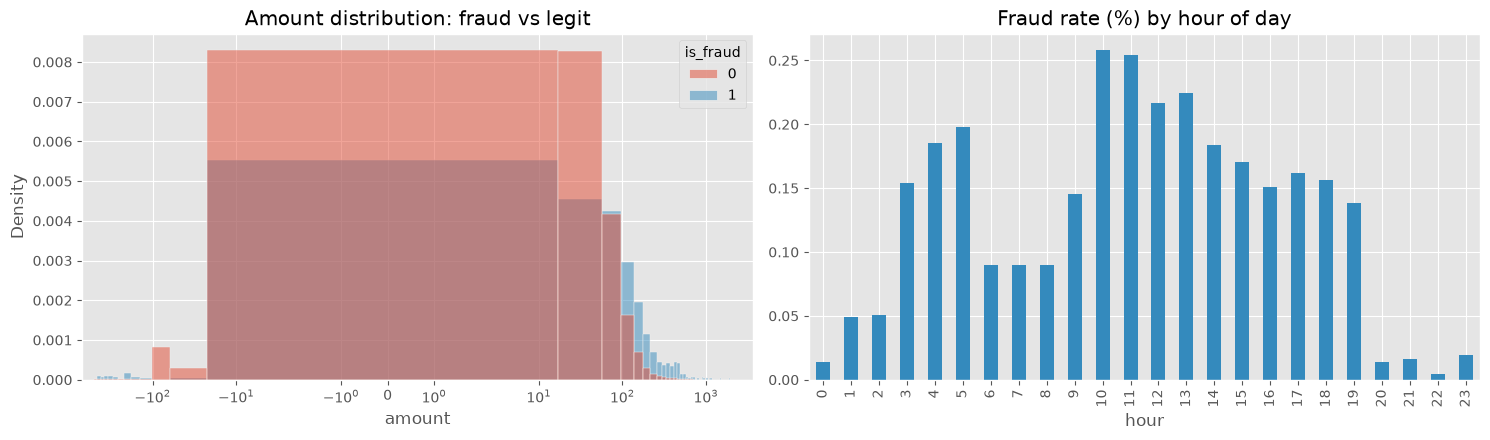

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=df.sample(500_000, random_state=0), x="amount", hue="is_fraud", stat="density",
             common_norm=False, bins=100, ax=axes[0]).set(xscale="symlog", title="Amount distribution: fraud vs legit")
(df.groupby("hour").is_fraud.mean() * 100).plot.bar(ax=axes[1], title="Fraud rate (%) by hour of day", color="C1")
plt.tight_layout()

### Fraud patterns drift over time
The fraud rate by channel changes sharply between years: online fraud dominates 2012–2016, while 2017–2019 fraud is concentrated at **foreign merchants**. A fixed rule set tuned on one period would degrade on the next — a key motivation for retrainable ML models and for a **time-based** evaluation.

channel,foreign,in-person US,online
year,,,
2010,5.288%,0.000%,2.572%
2011,0.034%,0.000%,0.037%
2012,0.000%,0.029%,0.701%
2013,0.000%,0.026%,1.069%
2014,0.000%,0.013%,0.520%
2015,0.000%,0.040%,1.628%
2016,0.000%,0.043%,1.823%
2017,2.837%,0.000%,0.000%
2018,22.689%,0.002%,0.075%


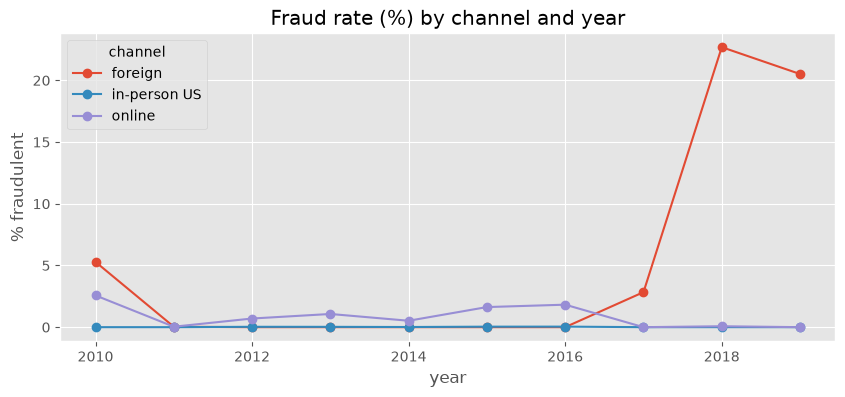

In [6]:
drift = df.assign(year=df.date.dt.year).pivot_table(index="year", columns="channel", values="is_fraud", aggfunc="mean")
ax = (drift * 100).plot(marker="o", figsize=(10, 4), title="Fraud rate (%) by channel and year")
ax.set_ylabel("% fraudulent"); drift.style.format("{:.3%}")

In [7]:
top_mcc = (df.groupby("mcc_description", observed=True).is_fraud.agg(["size", "sum", "mean"])
           .query("size > 5000").sort_values("mean", ascending=False).head(12))
top_mcc.columns = ["transactions", "frauds", "fraud_rate"]
top_mcc

,transactions,frauds,fraud_rate
mcc_description,,,
Passenger Railways,11877,238,0.0200
"Amusement Parks, Carnivals, Circuses",7735,123,0.0159
"Florists Supplies, Nursery Stock and Flowers",6051,96,0.0159
Non-Precious Metal Services,7003,102,0.0146
Gardening Supplies,10689,137,0.0128
Industrial Equipment and Supplies,10591,129,0.0122
Non-Ferrous Metal Foundries,7342,88,0.0120
"Digital Goods - Media, Books, Apps",41967,449,0.0107
Semiconductors and Related Devices,10671,112,0.0105


In [8]:
err = df.assign(errors=df.errors.astype(str).replace("nan", "none")).groupby("errors").is_fraud.agg(["size", "mean"])
err.sort_values("size", ascending=False).head(10)

,size,mean
errors,,
Insufficient Balance,87686,0.0019
Bad PIN,21488,0.0052
Technical Glitch,17776,0.0017
Bad Card Number,5235,0.0113
Bad CVV,4091,0.0340
Bad Expiration,4086,0.0132
Bad Zipcode,767,0.0000
"Bad PIN,Insufficient Balance",198,0.0051
"Insufficient Balance,Technical Glitch",163,0.0000


## 3. Feature engineering
Implemented in `src/fraud/features.py`. All behavioural features use only **earlier** transactions of the same card/client
(verified in `tests/test_features.py`), so they can be computed identically at scoring time.

| Group | Examples |
|---|---|
| Transaction | amount, log amount, refund, hour, weekday, night, online, foreign, multi-hot error codes |
| Behaviour (past-only) | seconds since previous txn, txns & spend in last 1h/24h, amount z-score vs card's history, first time at merchant / category / state, foreign & online txns in last 24h / 7d, client-level 24h velocity |
| Card | dark-web exposure, chip, credit limit, amount / limit, card age, years since PIN change, expired |
| Customer | age, credit score, income, debt, debt-to-income, income vs area |
| Anomaly | Isolation Forest score (unsupervised), fed into the supervised models |

In [9]:
behav = ["amount_zscore_card", "txn_count_24h", "new_merchant_for_card", "new_state_for_card",
         "card_foreign_count_7d", "card_on_dark_web", "has_error"]
df.groupby("is_fraud")[behav].mean().T.rename(columns={0: "legit (mean)", 1: "fraud (mean)"})

is_fraud,legit (mean),fraud (mean)
amount_zscore_card,-0.0004,1.2618
txn_count_24h,1.9166,3.1084
new_merchant_for_card,0.0489,0.5653
new_state_for_card,0.0067,0.0409
card_foreign_count_7d,0.0861,0.8121
card_on_dark_web,0.0000,0.0000
has_error,0.0159,0.0427


## 4. Models and time-based evaluation
* **Train:** 2010-01 → 2018-06 · **Validation:** 2018-07 → 2018-12 (early stopping + threshold choice) · **Test:** 2019 (untouched).
* Fraud is ~0.15% of transactions, so we report **PR-AUC** (average precision) as the headline metric,
  plus recall at 1% false-positive rate and precision/recall at the chosen threshold.

In [10]:
print(json.dumps(json.loads((config.MODELS_DIR / "run_info.json").read_text()), indent=2))
metrics = pd.DataFrame(json.loads((config.MODELS_DIR / "metrics.json").read_text())).T
metrics[["pr_auc", "roc_auc", "recall_at_1pct_fpr", "precision", "recall", "f1", "flag_rate", "tp", "fp", "fn"]]

{
  "sample": null,
  "n_labelled": 8914963,
  "split_sizes": {
    "train": 7666929,
    "test": 777339,
    "valid": 470695
  },
  "fraud_rate": 0.0014954633014180765,
  "lgbm_best_iteration": 233
}


,pr_auc,roc_auc,recall_at_1pct_fpr,precision,recall,f1,flag_rate,tp,fp,fn
Rule-based baseline,0.0638,0.9838,0.3541,0.0462,1.0000,0.0884,0.0378,"1,360.0000","28,053.0000",0.0000
Isolation Forest,0.0428,0.9541,0.2890,0.0697,0.1404,0.0931,0.0035,191.0000,"2,551.0000","1,169.0000"
Logistic Regression,0.2783,0.9929,0.8044,0.2925,0.4596,0.3574,0.0027,625.0000,"1,512.0000",735.0000
LightGBM,0.7110,0.9981,0.9559,0.7773,0.5647,0.6542,0.0013,768.0000,220.0000,592.0000


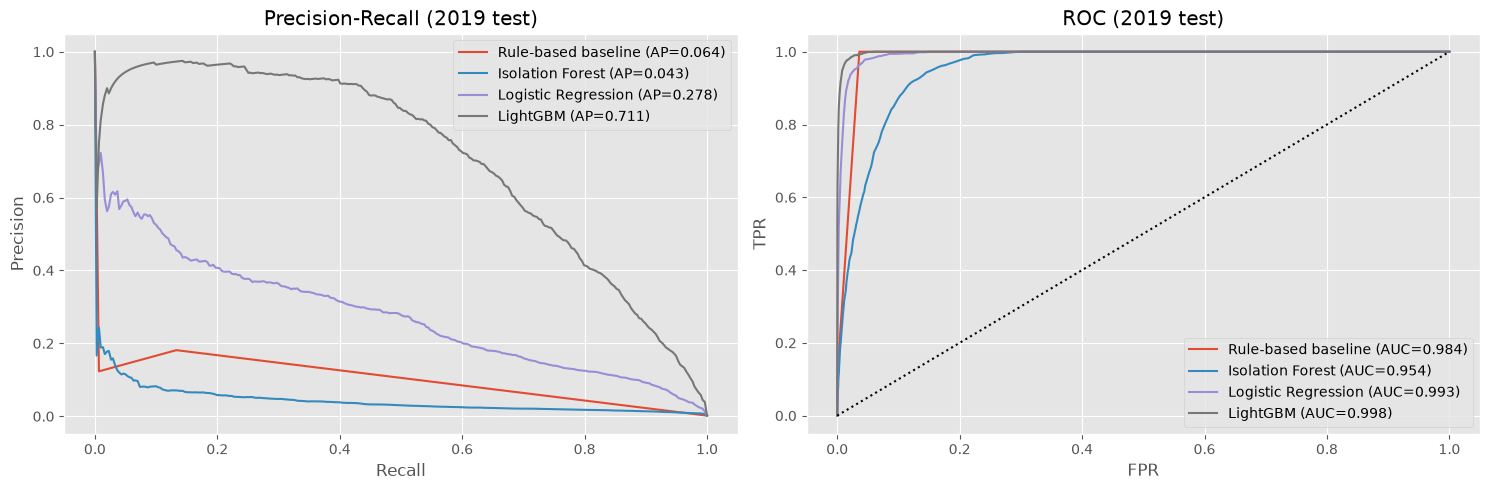

In [11]:
curves = json.loads((config.MODELS_DIR / "curves.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, c in curves.items():
    axes[0].plot(c["pr"]["recall"], c["pr"]["precision"], label=f"{name} (AP={metrics.loc[name, 'pr_auc']:.3f})")
    axes[1].plot(c["roc"]["fpr"], c["roc"]["tpr"], label=f"{name} (AUC={metrics.loc[name, 'roc_auc']:.3f})")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (2019 test)"); axes[0].legend()
axes[1].plot([0, 1], [0, 1], "k:"); axes[1].set(xlabel="FPR", ylabel="TPR", title="ROC (2019 test)"); axes[1].legend()
plt.tight_layout()

### Rule-based baseline in detail
Each rule on its own (2019 test):

In [12]:
pd.read_csv(config.MODELS_DIR / 'rule_stats.csv', index_col=0).style.format('{:.2%}')

,fires_on_pct_of_txns,precision,recall
Amount > 5x card's usual spend (and > $200),1.32%,1.28%,9.63%
Card seen on dark web,0.00%,0.00%,0.00%
Foreign merchant,0.85%,20.51%,100.00%
Security error (bad CVV / PIN / card no. / expiry),0.40%,1.03%,2.35%
3+ transactions on card within 1 hour,1.29%,0.17%,1.25%
New state for card and amount > $300,0.06%,2.16%,0.74%


## 5. LightGBM: thresholds and errors

Thresholds chosen on validation: {'flag': 0.15586473047733307, 'review': 0.0814753994345665, 'valid_f1_at_flag': 0.782922429344558, 'target_recall': 0.8}


risk_level
Low       776008
High         988
Medium       343
Name: count, dtype: int64
              size  sum   mean
risk_level                    
High           988  768 0.7773
Low         776008  473 0.0006
Medium         343  119 0.3469


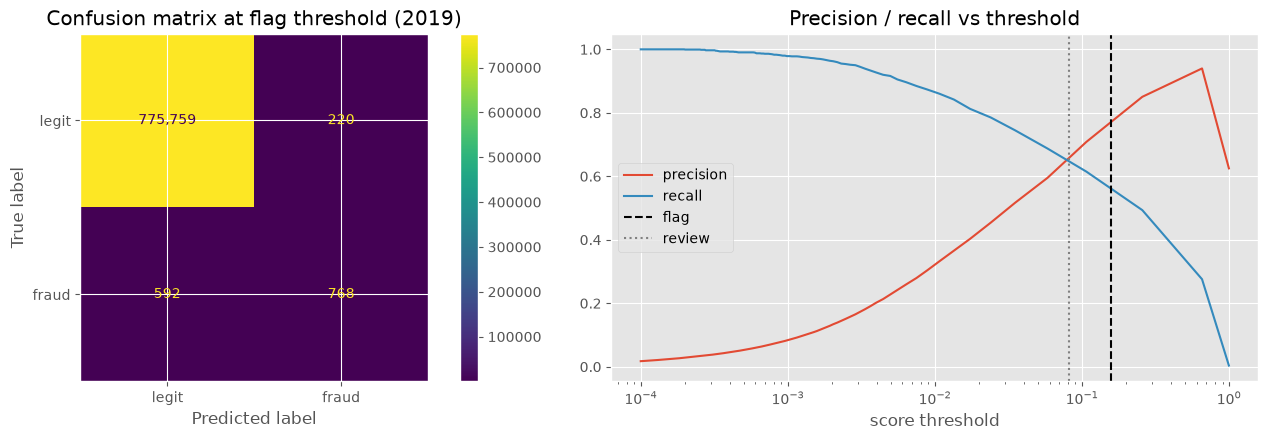

In [13]:
scored = pd.read_parquet(config.SCORED_TEST_PARQUET)
thr = json.loads((config.MODELS_DIR / "thresholds.json").read_text())["LightGBM"]
print("Thresholds chosen on validation:", thr)
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ConfusionMatrixDisplay.from_predictions(scored.is_fraud, scored.fraud_score >= thr["flag"],
                                        display_labels=["legit", "fraud"], ax=axes[0], values_format=",")
axes[0].set_title("Confusion matrix at flag threshold (2019)")
ts = np.quantile(scored.fraud_score, np.linspace(0.90, 0.99999, 200))
pr = [(scored.is_fraud[scored.fraud_score >= t].mean(), scored.is_fraud[scored.fraud_score >= t].sum() / scored.is_fraud.sum()) for t in ts]
axes[1].plot(ts, [p for p, _ in pr], label="precision"); axes[1].plot(ts, [r for _, r in pr], label="recall")
axes[1].axvline(thr["flag"], ls="--", c="k", label="flag"); axes[1].axvline(thr["review"], ls=":", c="grey", label="review")
axes[1].set(xscale="log", xlabel="score threshold", title="Precision / recall vs threshold"); axes[1].legend()
plt.tight_layout()
print(scored.risk_level.value_counts())
print(scored.groupby("risk_level").is_fraud.agg(["size", "sum", "mean"]))

## 6. Explainability
Global feature importance and SHAP values show *why* the model flags transactions — important for analysts reviewing alerts.

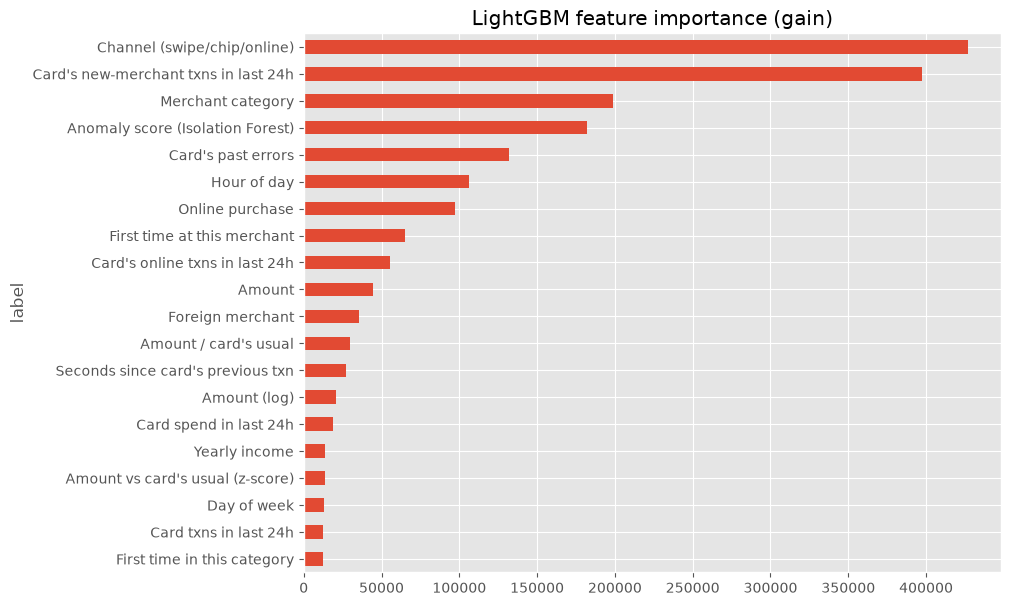

In [14]:
imp = pd.read_csv(config.MODELS_DIR / "feature_importance.csv").head(20)
imp["label"] = imp.feature.map(lambda f: explain.FEATURE_LABELS.get(f, f))
imp[::-1].plot.barh(x="label", y="gain", figsize=(9, 7), legend=False, title="LightGBM feature importance (gain)");

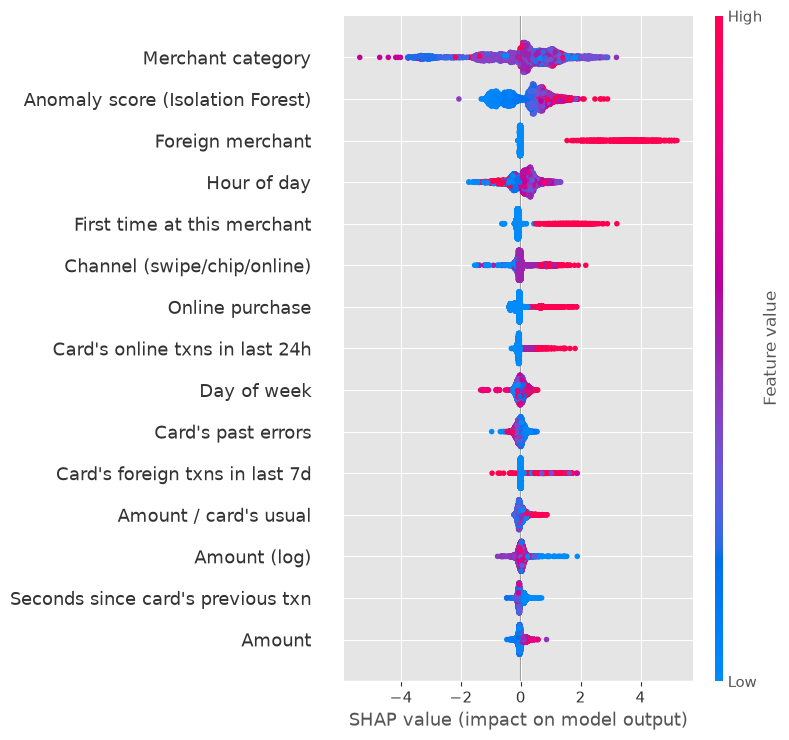

In [15]:
import shap
lgbm = joblib.load(config.MODELS_DIR / "lgbm.joblib")
expl = explain.explainer(lgbm)
sample = pd.concat([scored[scored.is_fraud == 1].sample(500, random_state=0),
                    scored[scored.is_fraud == 0].sample(4500, random_state=0)])
Xs = features.model_matrix(sample)[config.MODEL_FEATURES]
sv = explain.shap_values(expl, Xs)
shap.summary_plot(sv, Xs.rename(columns=explain.FEATURE_LABELS), max_display=15, show=False)

In [16]:
case = scored.nlargest(1, "fraud_score")
print(case[["id", "date", "amount", "merchant_city", "merchant_state", "mcc_description", "fraud_score", "is_fraud"]].T)
explain.top_reasons(expl, features.model_matrix(case)[config.MODEL_FEATURES], k=8)

                                       6982
id                                 22339477
date                    2019-01-03 16:47:00
amount                               8.0900
merchant_city                          Rome
merchant_state                        Italy
mcc_description  Precious Stones and Metals
fraud_score                          0.9991
is_fraud                                  1


,feature,label,value,contribution
0,is_foreign,Foreign merchant,1.0000,3.3969
1,mcc,Merchant category,"5,094.0000",2.3746
2,new_merchant_for_card,First time at this merchant,1.0000,2.3002
3,if_anomaly_score,Anomaly score (Isolation Forest),0.5062,1.9359
4,card_online_count_24h,Card's online txns in last 24h,2.0000,1.2866
5,hour,Hour of day,16.0000,0.9925
6,card_foreign_count_7d,Card's foreign txns in last 7d,3.0000,0.6860
7,card_prev_error_count,Card's past errors,41.0000,0.6736


## 7. Conclusions
* The ML model combines dozens of weak signals (spend deviation, velocity, merchant novelty, channel, error codes,
  card exposure) into one risk score and ranks fraud far better than unsupervised anomaly detection or a linear model.
* Static rules can look good **only when they happen to match the current fraud regime** (e.g. "foreign merchant" in 2017–19),
  and fail when patterns shift (online fraud in 2012–16). The ML pipeline learns new patterns on retraining.
* Two operating points: **High risk** (F1-optimal, for blocking/step-up auth) and **Medium** (≥80% recall on validation, for analyst review).
* Every alert comes with SHAP reasons, and the Streamlit app (`streamlit run app/streamlit_app.py`) lets analysts browse,
  investigate and score new transactions.

**Next steps:** periodic retraining / drift monitoring, cost-sensitive thresholds using transaction amount, and
sequence models over card histories.